In [26]:
# For your helper function to work you need to manually install the module because it doesn't come with Google Collab
!pip install pycountry_convert

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import pycountry_convert as mac
import numpy as np

# Helper functions

In [28]:
def country_to_continent(country_name):
  if not isinstance(country_name, str):
    return None
  try:
    country_alpha2 = mac.country_name_to_country_alpha2(country_name)
    country_continent_code = mac.country_alpha2_to_continent_code(country_alpha2)
    country_continent_name = mac.convert_continent_code_to_continent_name(country_continent_code)
    return country_continent_name
  except:
      return None

In [29]:
# I didn't want to do it manually every time so I created a function that recieves a dataframe and returnes the list of countries filtered by the continent.
# Later I've realised that I don't need to do the filtering manually either so I added that filtering directly.

# PS here is some more explanation:
# I don't know if I have to justify every new feature I put in but I guess I'll keep doing it for some time and by the time I get bored with it you'll probably believe me that I did it legit.
# I hope you read these or I'd get really annoyed. You requested no AI and now I'm wrestling for my life to not get an AD for new methods.
# I got the "Lengths must match to compare" error and googled it and found this article that suggested as one of the options the .isin() function which is perfect for my problem https://stackoverflow.com/questions/73353788/valueerror-lengths-must-match-to-compare-pandas

def filtered_by_continent(data_frame, continent):
  country_list = []

  for i in data_frame.groupby('Unnamed: 1').first().index:
    if country_to_continent(i) == continent:
      country_list.append(i)

  return data_frame[data_frame['Unnamed: 1'].isin(country_list)]

In [30]:
def continent_mean(data_frame, continent):
  return filtered_by_continent(data_frame, continent).groupby('Year', as_index=False)['Value'].mean()

In [31]:
def my_plot(data_frame, label, color):
  plt.plot(data_frame['Year'], data_frame['Value'], label=label, color=color)

In [32]:
def hebort_plot(standard_frame, country_name, y_label, title, filter = False):
  if filter == True:
    data_frame1 = standard_frame[standard_frame["Unnamed: 1"] == country_name.capitalize()].groupby('Year', as_index=False)['Value'].sum()
    data_frame2 = standard_frame[standard_frame["Unnamed: 1"] == "Slovakia"].groupby('Year', as_index=False)['Value'].sum()

    data_frame1 = pd.merge(left= data_frame1, right= population_data[population_data['Unnamed: 1'] == country_name.capitalize()], on= 'Year')
    data_frame2 = pd.merge(left= data_frame2, right= population_data[population_data['Unnamed: 1'] == 'Slovakia'], on= 'Year')

    data_frame1['Value'] = data_frame1['Value_x'] / (data_frame1['Value_y'] * 10**6) * 100
    data_frame2['Value'] = data_frame2['Value_x'] / (data_frame2['Value_y'] * 10**6) * 100

    continent_frame = filtered_by_continent(standard_frame, country_to_continent(country_name.capitalize())).groupby(['Year', 'Unnamed: 1'], as_index=False)['Value'].sum()
    continent_frame = pd.merge(left= continent_frame, right= population_data, on= ['Unnamed: 1', 'Year'])

    continent_frame['Value'] = continent_frame['Value_x'] / (continent_frame['Value_y'] * 10**6) * 100
    continent_frame = continent_frame.groupby('Year', as_index=False)['Value'].mean()
  else:
    data_frame1 = standard_frame[standard_frame["Unnamed: 1"] == country_name.capitalize()]
    data_frame2 = standard_frame[standard_frame["Unnamed: 1"] == "Slovakia"]

    continent_frame = continent_mean(standard_frame, country_to_continent(country_name.capitalize()))

  fig = plt.figure()
  fig.patch.set_facecolor('gold')

  my_plot(data_frame1, country_name.capitalize(), 'crimson')
  my_plot(data_frame2, 'Slovakia', 'navy')
  my_plot(continent_frame, country_to_continent(country_name.capitalize()), 'gold')

  plt.xlabel("Year")
  plt.ylabel(y_label)
  plt.legend()
  plt.title(title)
  plt.show()

**A quick explanation before you begin.** To give you the context needed, these comments were originally based above the first graph. They slowly came to be as I've iterated over several versions of plotting graphs, the final of which you saw in that function above.

In [33]:
#https://stackoverflow.com/questions/14088687/how-to-change-plot-background-color

#https://pandas.pydata.org/docs/dev/user_guide/groupby.html
# I was wondering why I got an error trying to access the columns of an aggregated dataframe. Turns out that when as_index=True which is the default it turns the grouped by column into an index as I've foun out in one of the Notes in the Aggregation section of the groupby manual:
# Aggregation functions will not return the groups that you are aggregating over as named columns when as_index=True, the default. The grouped columns will be the indices of the returned object.
# Passing as_index=False will return the groups that you are aggregating over as named columns, regardless if they are named indices or columns in the inputs."

# This was the last time I'm explaining something, if you think that some methods or functions I'll be using I couldn't come up on my own is because I couldn't, however you didn't prohibit stack overflow which has an answwer for literally everything. It's more or less like typing a question into an AI just that you get an answer from a couple of real people. (And I know that you know that, and that bringing us to actually search for something was your intention. And I'm really glad for that too. It's so much more fun finding out the things and learning them myself the only problem is that I don't really have time for that this year. Which is sad.)

# I know that the comments I left here no longer make sense because I moved the things into a separate function but that's what you have the revision history for isn't it?

# I think my version hystory is worth looking at. Especially to undrerstand what in the world happened to this one block of code over these two days.
# PS: sorry for the name, I could't think of a good name for the function

In [34]:
# Download UN data from google drive
# PS: I know that it's a lot of parameters I'm specifying but it just wouldn't work otherwise. The encoding is for the weird exotic characters in the city names, and I also need the thousands because your conversion method straight out wipes a lot of usable numbers that use 100,000,000 as dividers to NaN.
# Here you have the manual page, it's under the thousands parameter: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html

internet_data = pd.read_csv('https://github.com/MedardWork/Zadanie_ML_Datasets/raw/refs/heads/main/SYB68_314_202511_Internet%20Usage.csv', encoding='latin-1', header=1, thousands=",")
homicides_data = pd.read_csv('https://github.com/MedardWork/Zadanie_ML_Datasets/raw/refs/heads/main/SYB68_328_202511_Intentional%20homicides%20and%20other%20crimes.csv', encoding='latin-1', header=1, thousands=",")
pop_ferti_morti_data = pd.read_csv('https://github.com/MedardWork/Zadanie_ML_Datasets/raw/refs/heads/main/SYB68_246_202511_Population%20Growth,%20Fertility%20and%20Mortality%20Indicators.csv', encoding='latin-1', header=1, thousands=",")
migrant_data = pd.read_csv('https://github.com/MedardWork/Zadanie_ML_Datasets/raw/refs/heads/main/SYB68_327_202511_International%20Migrants%20and%20Refugees.csv', encoding='latin-1', header=1, thousands=",")
gdp_data = pd.read_csv('https://github.com/MedardWork/Zadanie_ML_Datasets/raw/refs/heads/main/SYB68_230_202511_GDP%20and%20GDP%20Per%20Capita.csv', encoding='latin-1', header=1, thousands=",")
teaching_staff_data = pd.read_csv('https://github.com/MedardWork/Zadanie_ML_Datasets/raw/refs/heads/main/SYB68_323_202511_Teaching%20Staff%20in%20education.csv', encoding='latin-1', header=1, thousands=",")
education_data = pd.read_csv('https://github.com/MedardWork/Zadanie_ML_Datasets/raw/refs/heads/main/SYB68_309_202511_Education.csv', encoding='latin-1', header=1, thousands=",")
pop_cc_uara_data = pd.read_csv('https://github.com/MedardWork/Zadanie_ML_Datasets/raw/refs/heads/main/SYB61_253_Population%20Growth%20Rates%20in%20Urban%20areas%20and%20Capital%20cities.csv', encoding='latin-1', header=1, thousands=",")
population_data = pd.read_csv('https://github.com/MedardWork/Zadanie_ML_Datasets/raw/refs/heads/main/SYB68_1_202511_Population,%20Surface%20Area%20and%20Density.csv', encoding='latin-1', header=1, thousands=',')

In [35]:
# Now let's filter the data for our use case

homicides_data = homicides_data[homicides_data['Series'] == 'Intentional homicide rates per 100,000']
life_expectancy_data = pop_ferti_morti_data[pop_ferti_morti_data['Series'] == 'Life expectancy at birth for both sexes (years)']
infant_mortality_data = pop_ferti_morti_data[pop_ferti_morti_data['Series'] == 'Under five mortality rate for both sexes (per 1,000 live births)']
migrant_data = migrant_data[migrant_data['Series'] == 'Total refugees and people in refugee-like situations (number)']
gdp_data = gdp_data[gdp_data['Series'] == 'GDP per capita (US dollars)']
teaching_staff_data = teaching_staff_data[teaching_staff_data['Series'].isin(['Teachers at lower secondary level', 'Teachers at primary level', 'Teachers at upper secondary level'])]
education_data = education_data[education_data['Series'].isin(['Students enrolled in lower secondary education (thousands)','Students enrolled in primary education (thousands)','Students enrolled in upper secondary education (thousands)'])]
pop_cc_uara_data = pop_cc_uara_data[pop_cc_uara_data['Series'] == 'Capital city population (as a percentage of total population)']

population_data = population_data[population_data['Series'] == 'Population mid-year estimates (millions)']


In [36]:
education_data['Value'] = education_data['Value'] * 10**3

In [37]:
homicides_data.groupby('Series').first().index

Index(['Intentional homicide rates per 100,000'], dtype='object', name='Series')

# Armenia

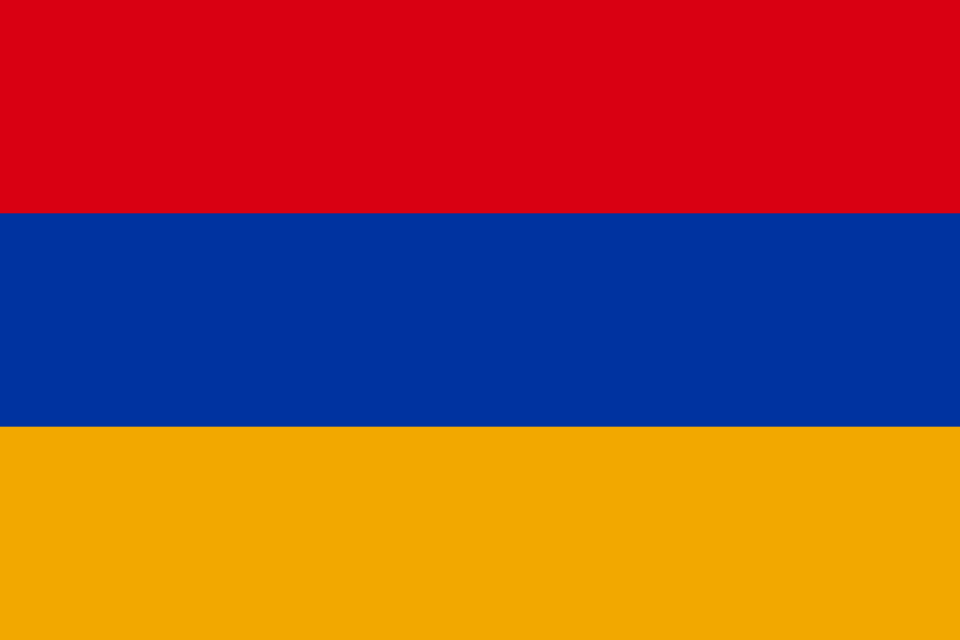

I think it's fair to say that since websites started to becoming user content based the Web 2.0 as they called it had started in the year 2004 and then rapidly expanded in a short 5 year period.

"The rapid technical advances that would propel the Internet into its place as a social system, which has completely transformed the way humans interact with each other, took place during a relatively short period from around 2005 to 2010" Wikipedia, History of the Internet

And we can see this very clearly on both armenian and the european graphs. Interestingly Slovakia was way above the asian average but we can see the difference thin out over time.

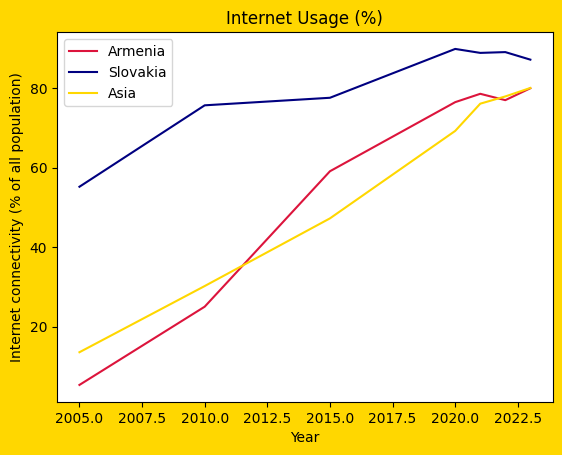

In [38]:
hebort_plot(internet_data, 'armenia', 'Internet connectivity (% of all population)', 'Internet Usage (%)')

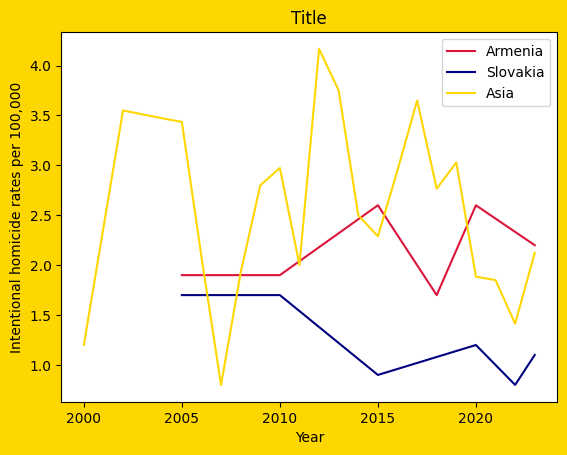

In [39]:
hebort_plot(homicides_data, 'armenia', 'Intentional homicide rates per 100,000', 'Title')

# Belgium

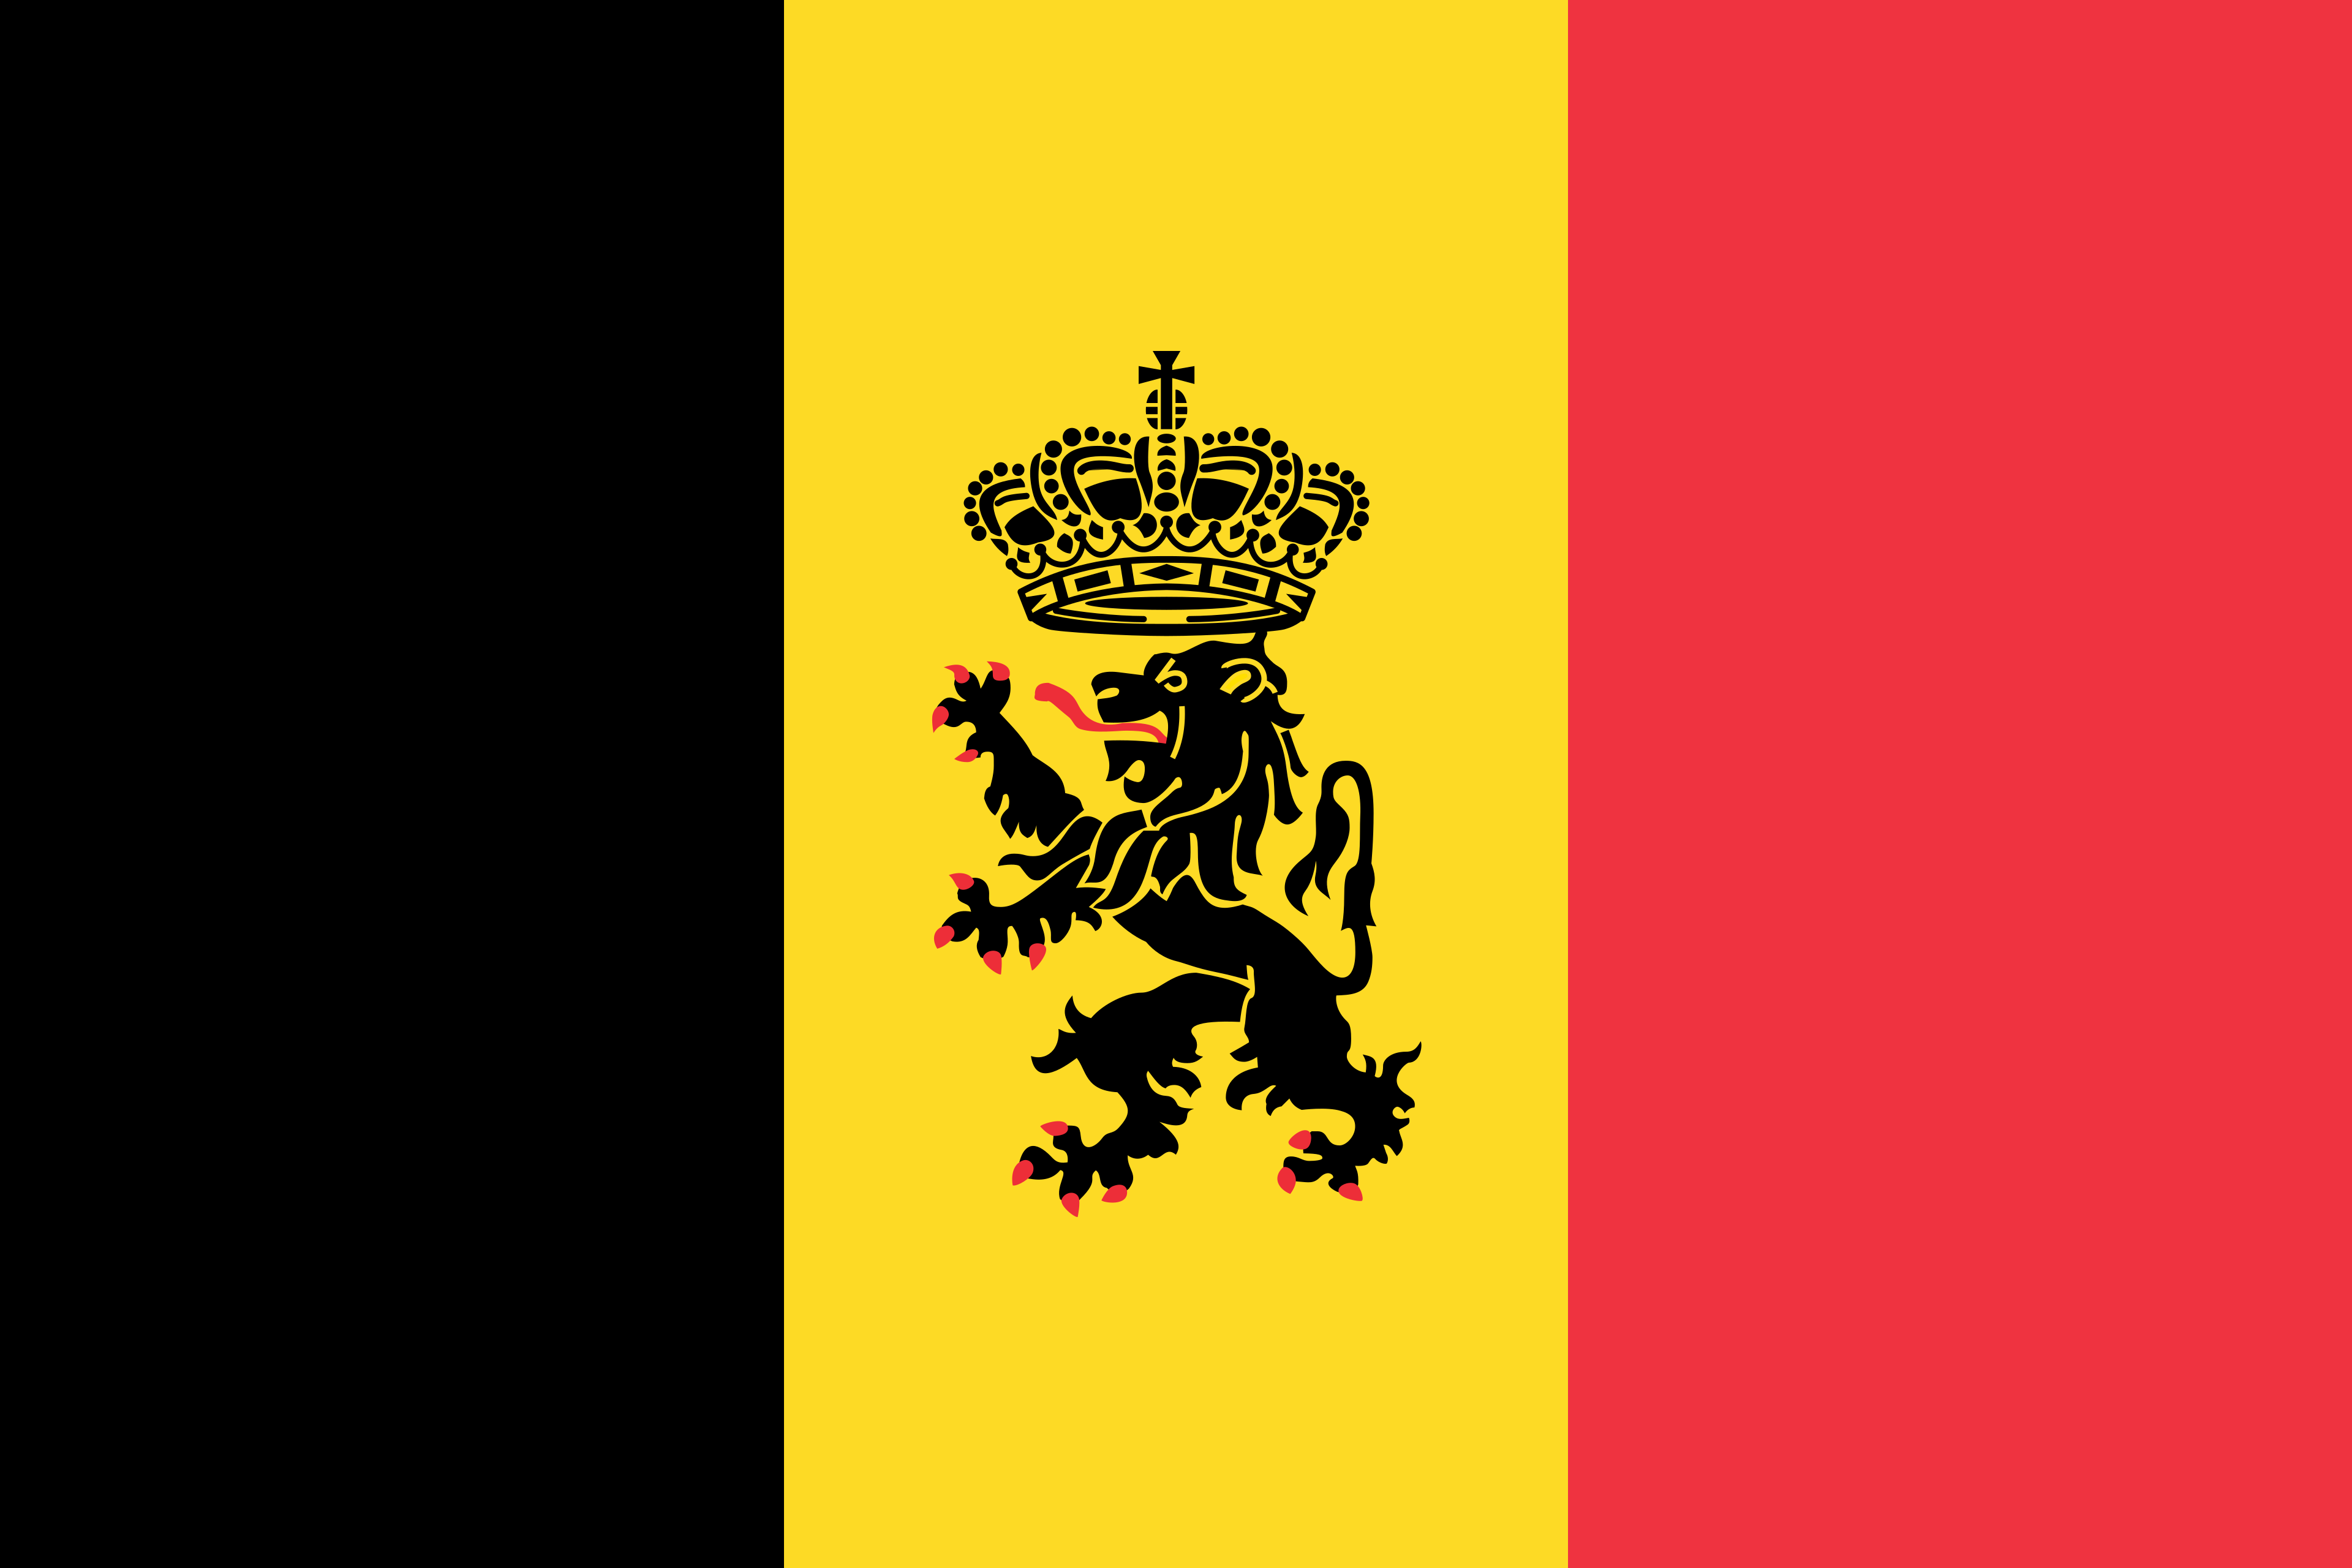

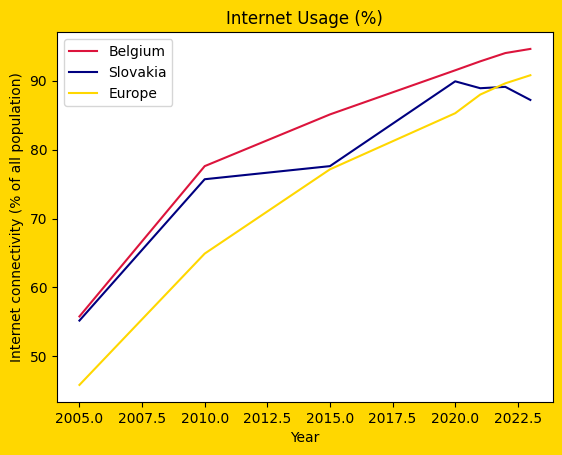

In [40]:
hebort_plot(internet_data, 'belgium', 'Internet connectivity (% of all population)', 'Internet Usage (%)')

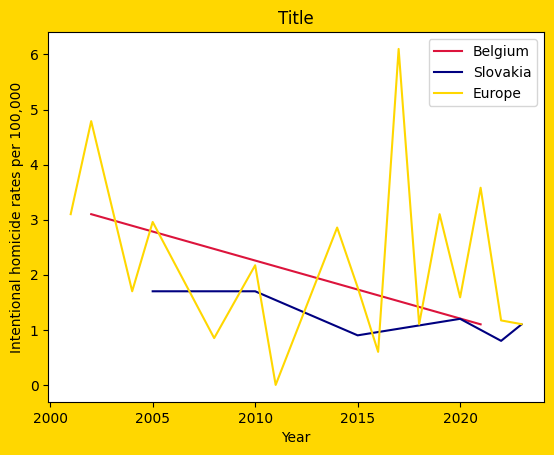

In [49]:
hebort_plot(homicides_data, 'belgium', 'Intentional homicide rates per 100,000', 'Title')

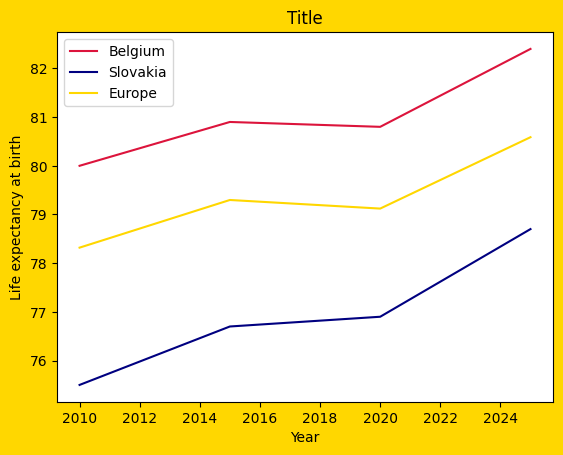

In [42]:
hebort_plot(life_expectancy_data, 'belgium', 'Life expectancy at birth', 'Title')

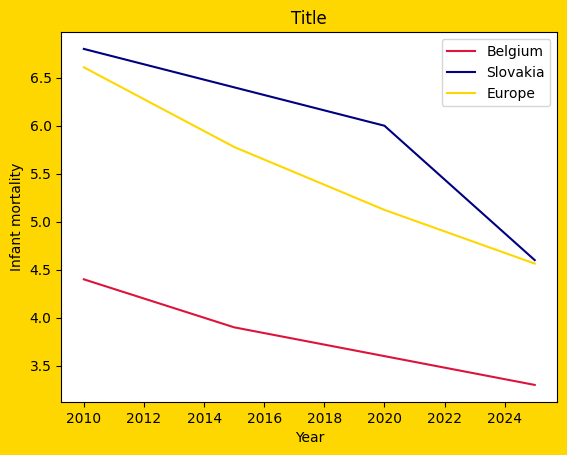

In [43]:
hebort_plot(infant_mortality_data, 'belgium', 'Infant mortality', 'Title')

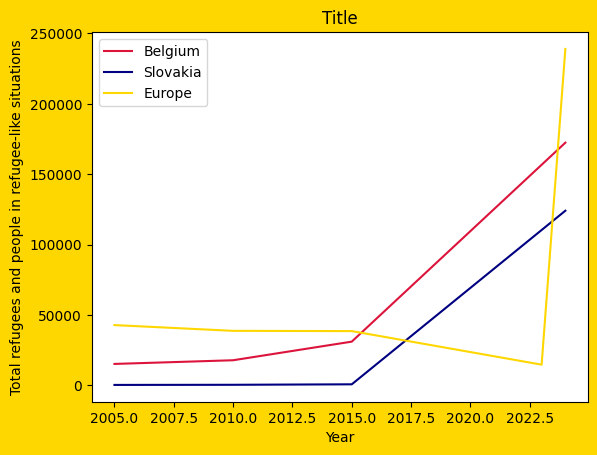

In [44]:
hebort_plot(migrant_data, 'belgium', 'Total refugees and people in refugee-like situations', 'Title')

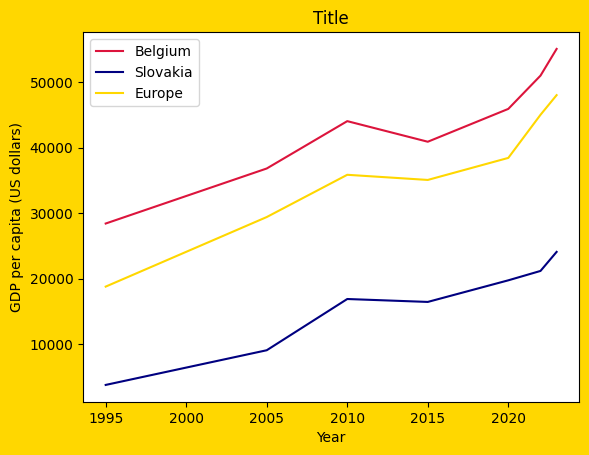

In [45]:
hebort_plot(gdp_data, 'belgium', 'GDP per capita (US dollars)', 'Title')

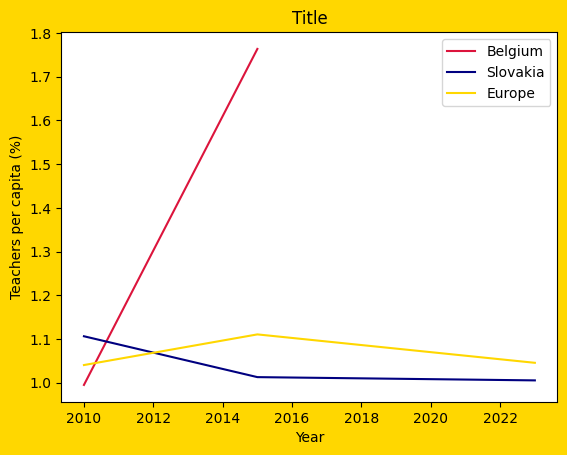

In [46]:
hebort_plot(teaching_staff_data, 'belgium', 'Teachers per capita (%)', 'Title', True)

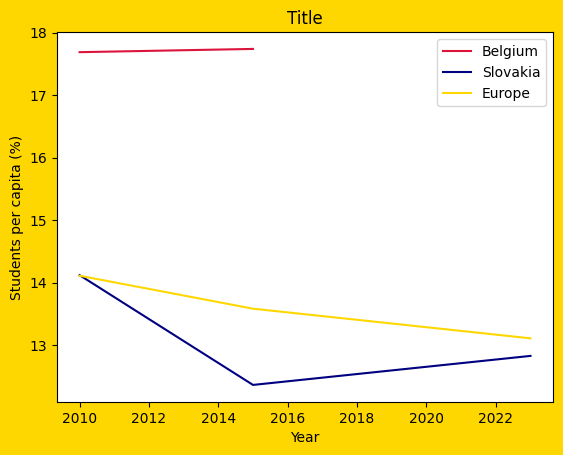

In [47]:
hebort_plot(education_data, 'belgium', 'Students per capita (%)', 'Title', True)

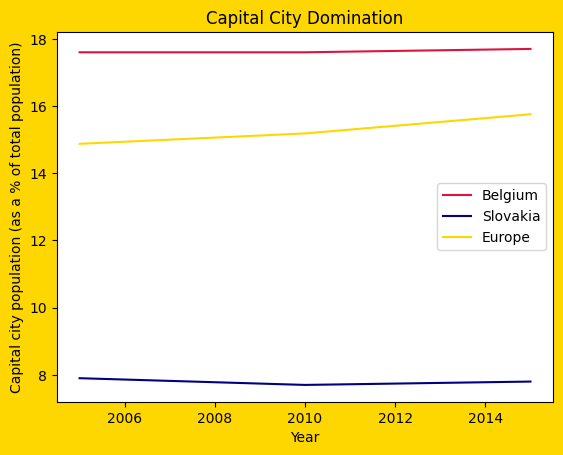

In [48]:
hebort_plot(pop_cc_uara_data, 'belgium', 'Capital city population (as a % of total population)', 'Capital City Domination')